In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from database import DataBase

           x1          y1          x2          y2           x3          y3  \
0  636.724121  448.433044  614.796265  626.451050  1325.051086  465.457901   
1  637.151611  446.454742  615.456604  625.792419  1324.725708  461.517120   
2  641.951782  448.647430  620.492798  626.412231  1313.949341  476.928040   
3  653.934204  445.660553  635.339905  627.435181  1302.213013  481.996246   
4  673.972778  446.188782  648.233887  627.172791  1282.222412  475.786377   

            x4          y4  
0  1354.070190  634.548828  
1  1354.858521  634.486572  
2  1355.977173  641.419373  
3  1357.950928  654.648804  
4  1357.000366  670.861328  


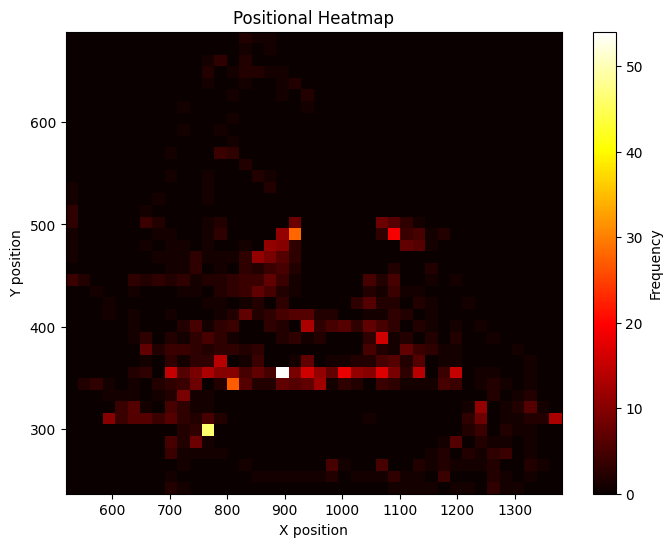

In [28]:
db = DataBase("InnovateDivision", [""])

prac_3 = db.get_data("SELECT * FROM practice_3")
df = pd.DataFrame(prac_3, columns=["x1", "y1", "x2", "y2", "x3", "y3", "x4", "y4"])

print(df.head())

plt.figure(figsize=(8, 6))

plt.hist2d(
    df['x1'],
    df['y1'],
    bins=40,
    cmap="hot"
)

plt.colorbar(label="Frequency")
plt.xlabel("X position")
plt.ylabel("Y position")
plt.title("Positional Heatmap")

plt.show()

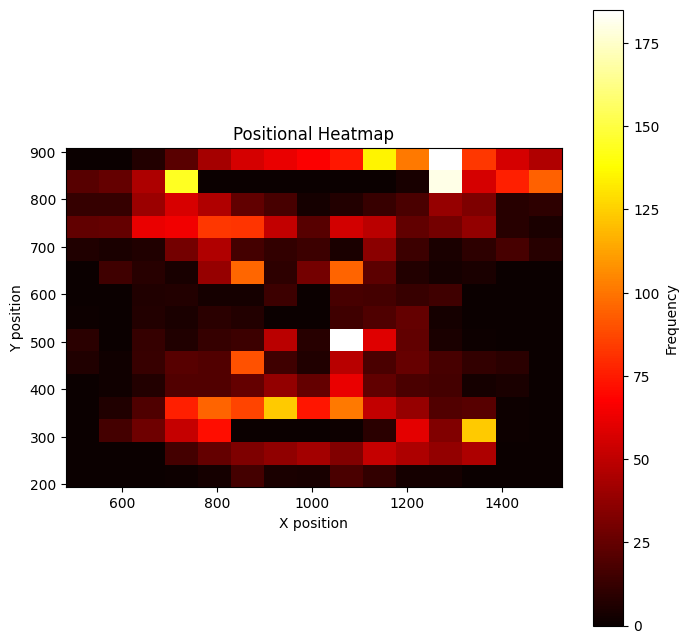

In [30]:
# columns holding the positions
x_cols = ["x1", "x2", "x3", "x4"]
y_cols = ["y1", "y2", "y3", "y4"]

# convert wide format into long format
points = pd.concat(
    [
        df[[x, y]].rename(columns={x: "x", y: "y"})
        for x, y in zip(x_cols, y_cols)
    ],
    ignore_index=True
)

# optional: drop missing coordinates
points = points.dropna(subset=["x", "y"])

plt.figure(figsize=(8, 8))

plt.hist2d(
    points["x"],
    points["y"],
    bins=15,
    cmap="hot"
)

plt.colorbar(label="Frequency")
plt.xlabel("X position")
plt.ylabel("Y position")
plt.title("Positional Heatmap")
plt.gca().set_aspect("equal")

plt.show()